# Analytical isothermal contour

This panel loads the completed analytical result from `new_paper_calculations/26-08-25/isothermal_analytic/`. Only finite positive velocities from cells with `task_status == "success"` enter the contours; failed cells remain masked.

In [1]:
from pathlib import Path

import numpy as np

WORKFLOW_RELATIVE_PATH = Path("new_paper_calculations/26-08-25/isothermal_analytic")
WORKFLOW_CANDIDATES = (Path.cwd() / WORKFLOW_RELATIVE_PATH, Path.cwd())
WORKFLOW_DIR = next(
    (
        candidate
        for candidate in WORKFLOW_CANDIDATES
        if (candidate / "isothermal-domain.npy").exists()
        and (candidate / "isothermal-analytic.npy").exists()
    ),
    None,
)
if WORKFLOW_DIR is None:
    raise FileNotFoundError(
        "Could not find the 26-08-25 analytical isothermal domain and contour payloads"
    )

domain_payload = np.load(
    WORKFLOW_DIR / "isothermal-domain.npy", allow_pickle=True
).item()
analytic_payload = np.load(
    WORKFLOW_DIR / "isothermal-analytic.npy", allow_pickle=True
).item()

if domain_payload.get("payload_kind") != "isothermal_domain":
    raise RuntimeError("Unexpected domain payload kind")
if analytic_payload.get("payload_kind") != "isothermal_analytic":
    raise RuntimeError("Unexpected analytical payload kind")
if domain_payload.get("domain_fingerprint") != analytic_payload.get("domain_fingerprint"):
    raise RuntimeError("Domain and analytical payload fingerprints differ")

task_status = np.asarray(analytic_payload["task_status"], dtype=object)
status_names, status_counts = np.unique(task_status, return_counts=True)
status_count_map = {
    str(status_name): int(status_count)
    for status_name, status_count in zip(status_names, status_counts)
}
terminal_count = int(np.count_nonzero(task_status != "pending"))
success_count = int(np.count_nonzero(task_status == "success"))

print(f"Workflow directory: {WORKFLOW_DIR.resolve()}")
print(f"Run complete: {bool(analytic_payload.get('run_complete'))}")
print(f"Terminal cells: {terminal_count}/{task_status.size}")
print(f"Successful cells: {success_count}/{task_status.size}")
print("Task-status counts:")
for status_name, status_count in status_count_map.items():
    print(f"  {status_name}: {status_count}")

if not bool(analytic_payload.get("run_complete")):
    raise RuntimeError("Analytical payload is not complete")
if terminal_count != task_status.size:
    raise RuntimeError("Analytical payload still contains pending cells")
if status_count_map.get("timeout", 0) != 0:
    raise RuntimeError("Analytical payload still contains timeout cells")

Workflow directory: /Users/janshao/NSM_related/new_paper_calculations/26-08-25/isothermal_analytic
Run complete: True
Terminal cells: 600/600
Successful cells: 599/600
Task-status counts:
  exception: 1
  success: 599


Successful analytical cells: 599/600
Velocity range: 21.40--2949358.01 m/s
Saved /Users/janshao/NSM_related/local_analysis_results/26SU-14/isothermal-analytic-contour-26-08-25.png
Saved /Users/janshao/NSM_related/local_analysis_results/26SU-14/isothermal-analytic-contour-26-08-25.pdf


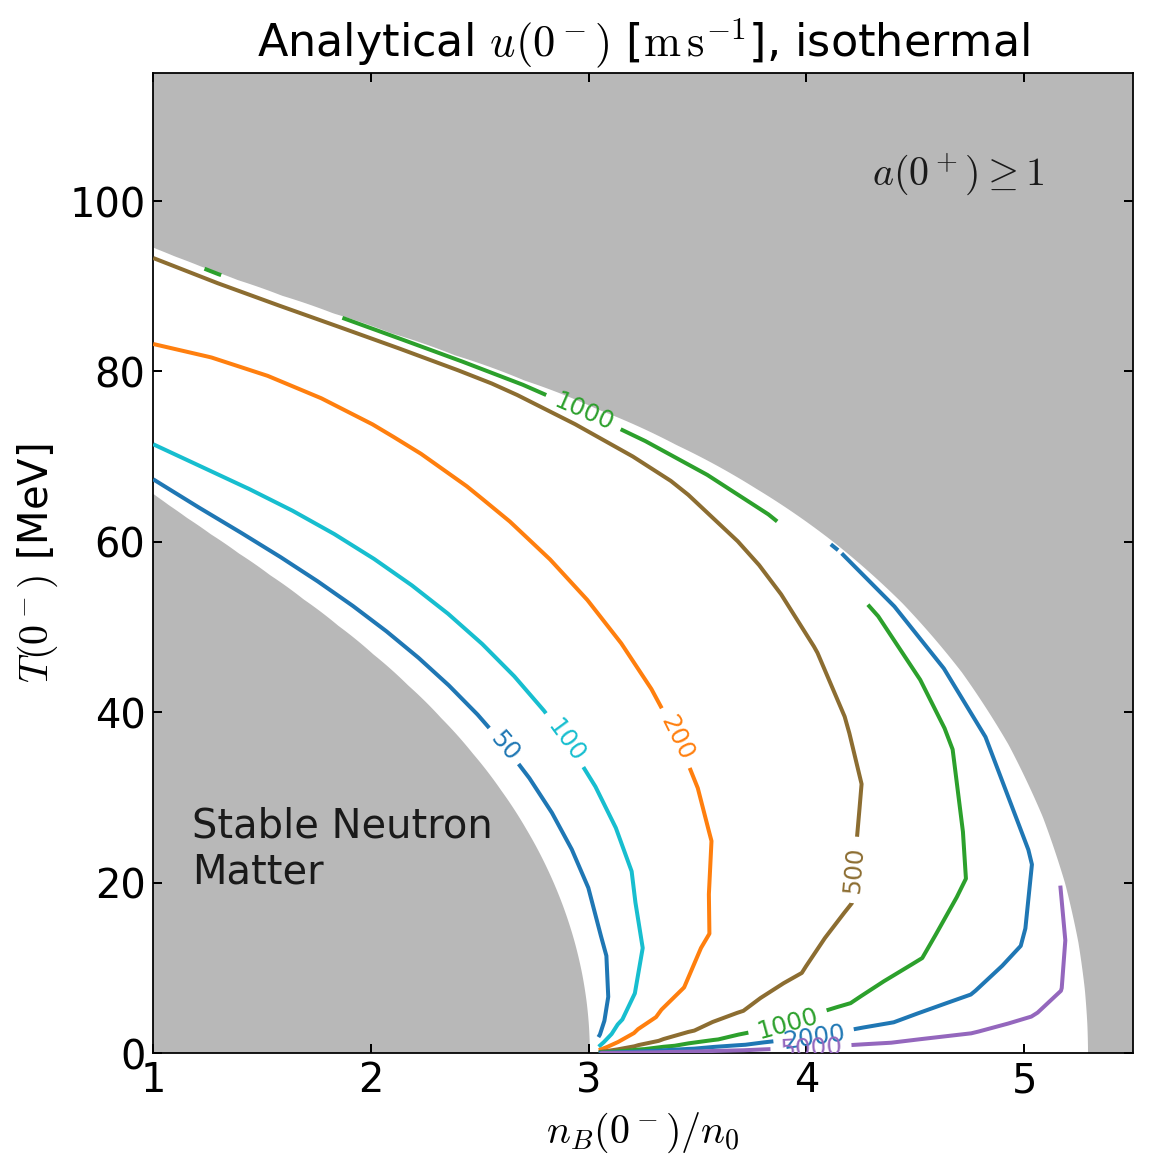

In [2]:
# Tunable plotting parameters
VELOCITY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0)
VELOCITY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#1f77b4", "#9467bd")
VELOCITY_CONTOUR_LINE_STYLE = "-"
VELOCITY_CONTOUR_LINE_WIDTH = 1.8
CONTOUR_LABEL_FONT_SIZE = 11
CONTOUR_LABEL_FORMAT = "%g"
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
CONTOUR_ZORDER = 3
BOUNDARY_INTERPOLATION_SAMPLES = 401
EXCLUDED_REGION_COLOR = "0.72"
EXCLUDED_REGION_ALPHA = 1.0
EXCLUDED_REGION_ZORDER = 0
OUTER_REGION_TEXT = r"$a(0^+)\geq 1$"
OUTER_REGION_TEXT_POSITION = (4.3, 102.0)
INNER_REGION_TEXT = "Stable Neutron\nMatter"
INNER_REGION_TEXT_POSITION = (1.18, 20.0)
REGION_TEXT_COLOR = "0.10"
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 5
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
BACKGROUND_COLOR = "white"
CONSTRAINED_LAYOUT = True
MATHTEXT_FONTSET = "cm"
MATHTEXT_ROMAN = "serif"
MATHTEXT_ITALIC = "serif:italic"
MATHTEXT_BOLD = "serif:bold"
X_LIMITS = (1.0, 5.5)
Y_LIMITS_MEV = (0.0, 115.0)
X_SCALE = "linear"
Y_SCALE = "linear"
BOX_ASPECT = 1.0
TITLE = r"Analytical $u(0^-)$ [$\mathrm{m\,s^{-1}}$], isothermal"
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
X_LABEL = r"$n_B(0^-)/n_0$"
Y_LABEL = r"$T(0^-)$ [MeV]"
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = "in"
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.8
OUTPUT_PNG = "local_analysis_results/26SU-14/isothermal-analytic-contour-26-08-25.png"
OUTPUT_PDF = "local_analysis_results/26SU-14/isothermal-analytic-contour-26-08-25.pdf"

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

transform = domain_payload["ray_transform"]
density_origin = float(transform["density_origin_over_n0"])
density_scale = float(transform["density_scale_over_n0"])
temperature_scale = float(transform["temperature_scale_MeV"])


def boundary_curve(root_key):
    ordered_records = sorted(
        domain_payload["boundary_ray_records"],
        key=lambda record: float(record["theta_rad"]),
    )
    theta_roots = np.asarray(
        [record["theta_rad"] for record in ordered_records], dtype=float
    )
    rho_roots = np.asarray(
        [record[root_key]["rho"] for record in ordered_records], dtype=float
    )
    finite_roots = np.isfinite(theta_roots) & np.isfinite(rho_roots)
    theta_roots = theta_roots[finite_roots]
    rho_roots = rho_roots[finite_roots]
    if theta_roots.size < 2:
        raise RuntimeError(f"Boundary {root_key!r} has fewer than two finite roots")
    theta = np.linspace(
        theta_roots[0], theta_roots[-1], BOUNDARY_INTERPOLATION_SAMPLES
    )
    rho = np.interp(theta, theta_roots, rho_roots)
    density = density_origin + density_scale * rho * np.cos(theta)
    temperature = temperature_scale * rho * np.sin(theta)
    return density, temperature


inner_density, inner_temperature = boundary_curve("delta_muB_equals_zero")
outer_density, outer_temperature = boundary_curve("a_0plus_equals_one")
density_grid = np.asarray(domain_payload["nB_0minus_over_n0_grid"], dtype=float)
temperature_grid = np.asarray(domain_payload["T_0minus_grid_MeV"], dtype=float)
velocity_m_s = np.asarray(analytic_payload["velocity_m_s_grid"], dtype=float)
successful_velocity = (
    (task_status == "success")
    & np.isfinite(velocity_m_s)
    & (velocity_m_s > 0.0)
)
if not np.any(successful_velocity):
    raise RuntimeError("The analytical payload has no successful positive velocities")
velocity_masked = np.ma.masked_where(~successful_velocity, velocity_m_s)
velocity_min = float(np.nanmin(velocity_m_s[successful_velocity]))
velocity_max = float(np.nanmax(velocity_m_s[successful_velocity]))
available_levels = tuple(
    level
    for level in VELOCITY_CONTOUR_LEVELS_M_S
    if velocity_min <= level <= velocity_max
)
level_to_color = dict(zip(VELOCITY_CONTOUR_LEVELS_M_S, VELOCITY_CONTOUR_COLORS))
available_colors = tuple(level_to_color[level] for level in available_levels)

mpl.rcParams.update(
    {
        "mathtext.fontset": MATHTEXT_FONTSET,
        "mathtext.rm": MATHTEXT_ROMAN,
        "mathtext.it": MATHTEXT_ITALIC,
        "mathtext.bf": MATHTEXT_BOLD,
    }
)

figure, axis = plt.subplots(
    figsize=FIGURE_SIZE,
    dpi=FIGURE_DPI,
    constrained_layout=CONSTRAINED_LAYOUT,
    facecolor=BACKGROUND_COLOR,
)
axis.set_facecolor(BACKGROUND_COLOR)

inner_polygon_x = np.concatenate(
    (inner_density, (X_LIMITS[0], inner_density[0]))
)
inner_polygon_y = np.concatenate(
    (inner_temperature, (Y_LIMITS_MEV[0], Y_LIMITS_MEV[0]))
)
axis.fill(
    inner_polygon_x,
    inner_polygon_y,
    color=EXCLUDED_REGION_COLOR,
    alpha=EXCLUDED_REGION_ALPHA,
    zorder=EXCLUDED_REGION_ZORDER,
)
outer_polygon_x = np.concatenate(
    (outer_density, (X_LIMITS[0], X_LIMITS[1], X_LIMITS[1], outer_density[0]))
)
outer_polygon_y = np.concatenate(
    (
        outer_temperature,
        (Y_LIMITS_MEV[1], Y_LIMITS_MEV[1], Y_LIMITS_MEV[0], Y_LIMITS_MEV[0]),
    )
)
axis.fill(
    outer_polygon_x,
    outer_polygon_y,
    color=EXCLUDED_REGION_COLOR,
    alpha=EXCLUDED_REGION_ALPHA,
    zorder=EXCLUDED_REGION_ZORDER,
)

speed_contours = axis.contour(
    density_grid,
    temperature_grid,
    velocity_masked,
    levels=available_levels,
    colors=available_colors,
    linestyles=VELOCITY_CONTOUR_LINE_STYLE,
    linewidths=VELOCITY_CONTOUR_LINE_WIDTH,
    zorder=CONTOUR_ZORDER,
)
axis.clabel(
    speed_contours,
    speed_contours.levels,
    inline=CONTOUR_LABEL_INLINE,
    fmt=CONTOUR_LABEL_FORMAT,
    fontsize=CONTOUR_LABEL_FONT_SIZE,
    inline_spacing=CONTOUR_LABEL_INLINE_SPACING,
)
axis.text(
    *OUTER_REGION_TEXT_POSITION,
    OUTER_REGION_TEXT,
    color=REGION_TEXT_COLOR,
    fontsize=REGION_TEXT_FONT_SIZE,
    zorder=REGION_TEXT_ZORDER,
)
axis.text(
    *INNER_REGION_TEXT_POSITION,
    INNER_REGION_TEXT,
    color=REGION_TEXT_COLOR,
    fontsize=REGION_TEXT_FONT_SIZE,
    zorder=REGION_TEXT_ZORDER,
)
axis.set_xlim(*X_LIMITS)
axis.set_ylim(*Y_LIMITS_MEV)
axis.set_xscale(X_SCALE)
axis.set_yscale(Y_SCALE)
axis.set_box_aspect(BOX_ASPECT)
axis.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE, pad=TITLE_PAD)
axis.tick_params(
    direction=TICK_DIRECTION,
    top=TICKS_TOP,
    right=TICKS_RIGHT,
    length=TICK_LENGTH,
    width=TICK_WIDTH,
    labelsize=TICK_LABEL_FONT_SIZE,
)
for spine in axis.spines.values():
    spine.set_linewidth(SPINE_LINE_WIDTH)

output_png = Path.cwd() / OUTPUT_PNG
output_pdf = Path.cwd() / OUTPUT_PDF
output_png.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(output_png, dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
figure.savefig(output_pdf, facecolor=BACKGROUND_COLOR)
print(f"Successful analytical cells: {success_count}/{task_status.size}")
print(f"Velocity range: {velocity_min:.2f}--{velocity_max:.2f} m/s")
print(f"Saved {output_png}")
print(f"Saved {output_pdf}")
plt.show()

## Numerical isothermal contour: preserved baseline and targeted repairs

The next two cells load the immutable 26-08-27 results and, when present, the targeted repair checkpoint in `new_paper_calculations/26-09-16/isothermal_numeric_repair/`. Only validated numerical contour segments extend the baseline curves. Running these cells does not run any BVP calculations.


In [3]:
from pathlib import Path

import numpy as np

NUMERICAL_WORKFLOW_RELATIVE_PATH = Path("new_paper_calculations/26-09-16/isothermal_numeric_repair")
NUMERICAL_TARGETED_DIR = Path.cwd() / "new_paper_calculations/26-09-21/isothermal_targeted"
NUMERICAL_TARGETED_PATH = NUMERICAL_TARGETED_DIR / "isothermal-targeted.npy"
NUMERICAL_WORKFLOW_CANDIDATES = (
    NUMERICAL_TARGETED_DIR / "inputs" if NUMERICAL_TARGETED_PATH.exists() else Path("/__no_targeted_snapshot__"),
    Path.cwd() / NUMERICAL_WORKFLOW_RELATIVE_PATH,
    Path.cwd(),
)
NUMERICAL_WORKFLOW_DIR = next(
    (
        candidate
        for candidate in NUMERICAL_WORKFLOW_CANDIDATES
        if (candidate / "isothermal-domain.npy").exists()
        and (candidate / "isothermal-numerical.npy").exists()
    ),
    None,
)
if NUMERICAL_WORKFLOW_DIR is None:
    raise FileNotFoundError(
        "Could not find the numerical isothermal baseline payloads in the repair workflow"
    )

numerical_domain_payload = np.load(
    NUMERICAL_WORKFLOW_DIR / "isothermal-domain.npy", allow_pickle=True
).item()
numerical_payload = np.load(
    NUMERICAL_WORKFLOW_DIR / "isothermal-numerical.npy", allow_pickle=True
).item()

if numerical_domain_payload.get("payload_kind") != "isothermal_domain":
    raise RuntimeError("Unexpected numerical-domain payload kind")
if numerical_payload.get("payload_kind") != "isothermal_numerical":
    raise RuntimeError("Unexpected numerical payload kind")
if numerical_domain_payload.get("domain_fingerprint") != numerical_payload.get("domain_fingerprint"):
    raise RuntimeError("Numerical domain and checkpoint fingerprints differ")
numerical_task_status = np.asarray(numerical_payload["task_status"], dtype=object)
numerical_status_names, numerical_status_counts = np.unique(
    numerical_task_status, return_counts=True
)
numerical_status_count_map = {
    str(status_name): int(status_count)
    for status_name, status_count in zip(
        numerical_status_names, numerical_status_counts
    )
}
numerical_terminal_count = int(np.count_nonzero(numerical_task_status != "pending"))
numerical_success_count = int(np.count_nonzero(numerical_task_status == "success"))

print(f"Numerical workflow directory: {NUMERICAL_WORKFLOW_DIR.resolve()}")
print(f"Baseline checkpoint updated: {numerical_payload.get('updated_at_utc', 'unknown')}")
print(f"Baseline run complete: {bool(numerical_payload.get('run_complete'))}")
print(f"Terminal cells: {numerical_terminal_count}/{numerical_task_status.size}")
print(f"Successful cells: {numerical_success_count}/{numerical_task_status.size}")
print("Task-status counts:")
for status_name, status_count in numerical_status_count_map.items():
    print(f"  {status_name}: {status_count}")
# Load the small repair overlay; original successful grid records stay unchanged.
import sys
# A live kernel keeps the first import of these workflow helpers, so an edited
# module stays invisible to Run All unless the kernel is restarted.  Dropping
# them here makes a plain re-run pick up the current source.
for _stale_module in ("plot_targeted_contours", "plot_isothermal_contours",
                      "_repair_search", "_repair_common"):
    sys.modules.pop(_stale_module, None)
NUMERICAL_HELPER_DIR = Path.cwd() / NUMERICAL_WORKFLOW_RELATIVE_PATH
if str(NUMERICAL_HELPER_DIR.resolve()) not in sys.path:
    sys.path.insert(0, str(NUMERICAL_HELPER_DIR.resolve()))
from _repair_common import sha256 as repair_sha256
from plot_isothermal_contours import merged_contour_segments
NUMERICAL_REPAIR_PATH = NUMERICAL_WORKFLOW_DIR / "isothermal-contour-repair.npy"
numerical_repair_payload = (
    np.load(NUMERICAL_REPAIR_PATH, allow_pickle=True).item()
    if NUMERICAL_REPAIR_PATH.exists() else None
)
if numerical_repair_payload is not None:
    if numerical_repair_payload.get("payload_kind") != "isothermal_contour_repair":
        raise RuntimeError("Unexpected contour repair payload kind")
    for filename, expected_hash in numerical_repair_payload["baseline_hashes"].items():
        if repair_sha256(NUMERICAL_WORKFLOW_DIR / filename) != expected_hash:
            raise RuntimeError(f"Repair baseline hash mismatch: {filename}")
    print(f"Additional numerical solutions/anchors: {len(numerical_repair_payload['points'])}")
    print(f"Contour completion: {numerical_repair_payload.get('level_complete', {})}")
else:
    print("No repair checkpoint downloaded yet; displaying the preserved baseline.")

# Optional bounded-shot overlay; require the exact input snapshot.
if str(NUMERICAL_TARGETED_DIR.resolve()) not in sys.path:
    sys.path.insert(0, str(NUMERICAL_TARGETED_DIR.resolve()))
from plot_targeted_contours import merged_targeted_segments, accepted_root_groups, targeted_bridges
numerical_targeted_payload = (
    np.load(NUMERICAL_TARGETED_PATH, allow_pickle=True).item()
    if NUMERICAL_TARGETED_PATH.exists() else None
)
if numerical_targeted_payload is not None:
    if numerical_targeted_payload.get("payload_kind") != "isothermal_targeted":
        raise RuntimeError("Unexpected targeted payload kind")
    for filename, expected_hash in numerical_targeted_payload["identity"]["input_hashes"].items():
        if repair_sha256(NUMERICAL_WORKFLOW_DIR / filename) != expected_hash:
            raise RuntimeError(f"Targeted input mismatch: {filename}; download its immutable inputs/ folder")
    print(f"Targeted BVP calls: {len(numerical_targeted_payload['evaluations'])}/120")
    print(f"Certified targeted intervals: {sum(t.get('certified', False) and not t.get('children') for t in numerical_targeted_payload['targets'].values())}")
else:
    print("No bounded-shot checkpoint yet; showing saved repair roots as markers.")


Numerical workflow directory: /Users/janshao/NSM_related/new_paper_calculations/26-09-16/isothermal_numeric_repair
Baseline checkpoint updated: 2026-08-28T15:48:33.836440+00:00
Baseline run complete: True
Terminal cells: 600/600
Successful cells: 362/600
Task-status counts:
  cell_timeout: 194
  failure: 44
  success: 362
Additional numerical solutions/anchors: 396
Contour completion: {}
No bounded-shot checkpoint yet; showing saved repair roots as markers.


Preserved baseline successes: 362/600
Baseline velocity range: 20.09--3025.03 m/s
Saved /Users/janshao/NSM_related/local_analysis_results/26SU-14/isothermal-numerical-contour-repaired.png
Saved /Users/janshao/NSM_related/local_analysis_results/26SU-14/isothermal-numerical-contour-repaired.pdf


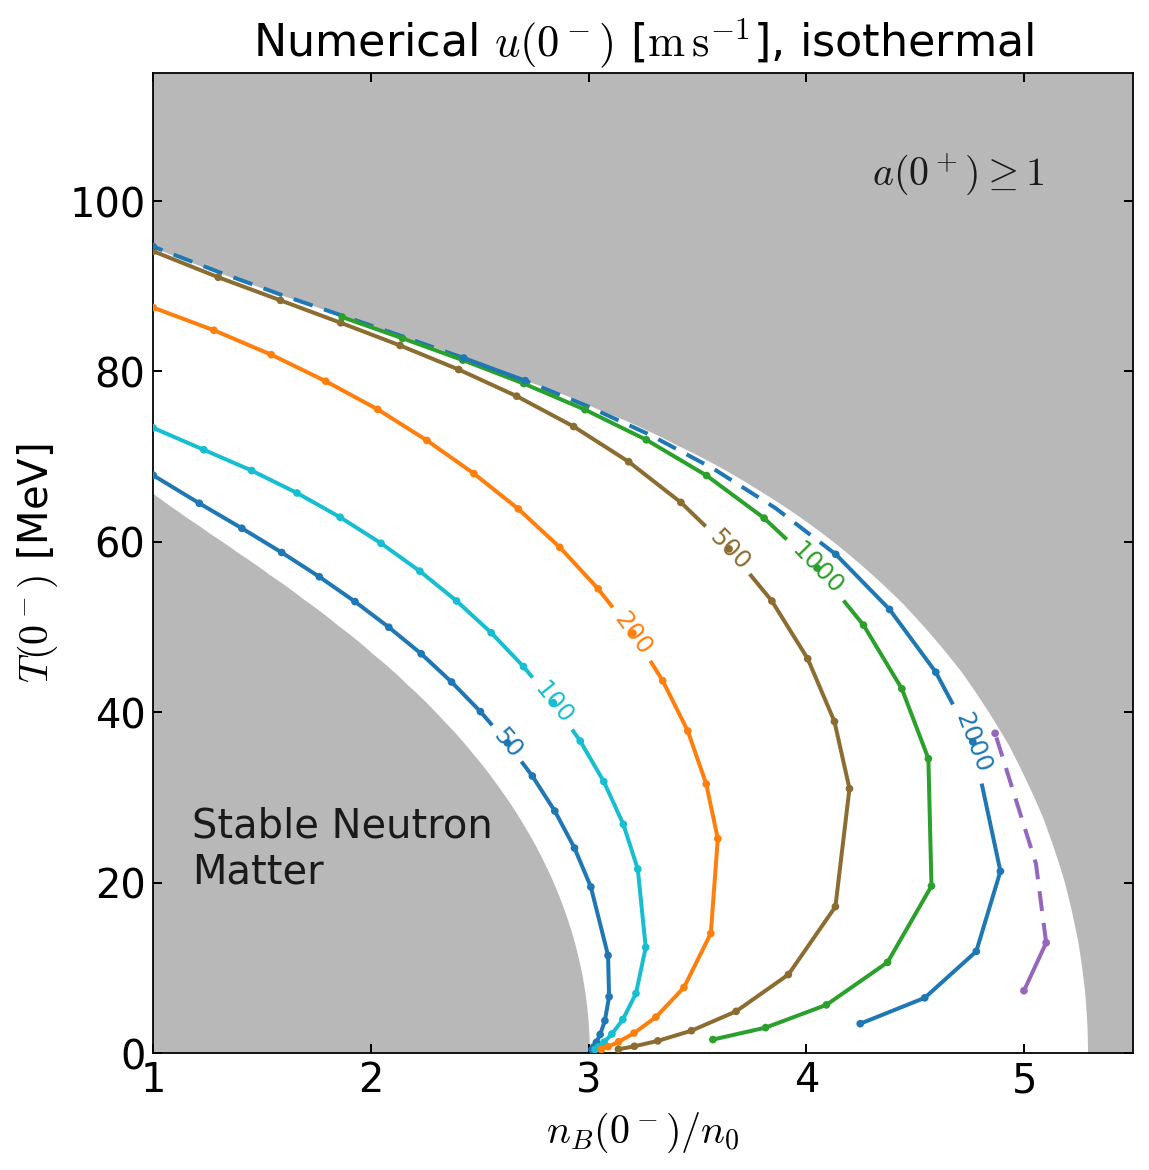

In [4]:
# Tunable plotting parameters
NUMERICAL_ROOT_MARKER_AREA = 12.0
NUMERICAL_ROOT_MARKER_STYLE = "o"
NUMERICAL_ROOT_MARKER_EDGE_COLOR = "none"
NUMERICAL_ROOT_MARKER_ALPHA = 1.0
NUMERICAL_ROOT_MARKER_ZORDER = 4
NUMERICAL_VELOCITY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0)
NUMERICAL_VELOCITY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#1f77b4", "#9467bd")
NUMERICAL_VELOCITY_CONTOUR_LINE_STYLE = "-"
NUMERICAL_VELOCITY_CONTOUR_LINE_WIDTH = 1.8
NUMERICAL_CONTOUR_LABEL_FONT_SIZE = 11
NUMERICAL_CONTOUR_LABEL_FORMAT = "%g"
NUMERICAL_CONTOUR_LABEL_INLINE = True
NUMERICAL_CONTOUR_LABEL_INLINE_SPACING = 4
NUMERICAL_CONTOUR_ZORDER = 3
NUMERICAL_BRIDGE_LINE_STYLE = (0, (5, 3))
NUMERICAL_BRIDGE_LINE_WIDTH = 1.8
NUMERICAL_BRIDGE_ZORDER = 2
NUMERICAL_BOUNDARY_INTERPOLATION_SAMPLES = 401
NUMERICAL_EXCLUDED_REGION_COLOR = "0.72"
NUMERICAL_EXCLUDED_REGION_ALPHA = 1.0
NUMERICAL_EXCLUDED_REGION_ZORDER = 0
NUMERICAL_OUTER_REGION_TEXT = r"$a(0^+)\geq 1$"
NUMERICAL_OUTER_REGION_TEXT_POSITION = (4.3, 102.0)
NUMERICAL_INNER_REGION_TEXT = "Stable Neutron\nMatter"
NUMERICAL_INNER_REGION_TEXT_POSITION = (1.18, 20.0)
NUMERICAL_REGION_TEXT_COLOR = "0.10"
NUMERICAL_REGION_TEXT_FONT_SIZE = 18
NUMERICAL_REGION_TEXT_ZORDER = 5
NUMERICAL_FIGURE_SIZE = (7.2, 7.2)
NUMERICAL_FIGURE_DPI = 160
NUMERICAL_EXPORT_DPI = 220
NUMERICAL_BACKGROUND_COLOR = "white"
NUMERICAL_CONSTRAINED_LAYOUT = True
NUMERICAL_MATHTEXT_FONTSET = "cm"
NUMERICAL_MATHTEXT_ROMAN = "serif"
NUMERICAL_MATHTEXT_ITALIC = "serif:italic"
NUMERICAL_MATHTEXT_BOLD = "serif:bold"
NUMERICAL_X_LIMITS = (1.0, 5.5)
NUMERICAL_Y_LIMITS_MEV = (0.0, 115.0)
NUMERICAL_X_SCALE = "linear"
NUMERICAL_Y_SCALE = "linear"
NUMERICAL_BOX_ASPECT = 1.0
NUMERICAL_TITLE = r"Numerical $u(0^-)$ [$\mathrm{m\,s^{-1}}$], isothermal"
NUMERICAL_TITLE_FONT_SIZE = 20
NUMERICAL_TITLE_PAD = 8
NUMERICAL_X_LABEL = r"$n_B(0^-)/n_0$"
NUMERICAL_Y_LABEL = r"$T(0^-)$ [MeV]"
NUMERICAL_AXIS_LABEL_FONT_SIZE = 18
NUMERICAL_TICK_LABEL_FONT_SIZE = 18
NUMERICAL_TICK_DIRECTION = "in"
NUMERICAL_TICKS_TOP = True
NUMERICAL_TICKS_RIGHT = True
NUMERICAL_TICK_LENGTH = 4
NUMERICAL_TICK_WIDTH = 0.9
NUMERICAL_SPINE_LINE_WIDTH = 0.8
NUMERICAL_OUTPUT_PNG = "local_analysis_results/26SU-14/isothermal-numerical-contour-repaired.png"
NUMERICAL_OUTPUT_PDF = "local_analysis_results/26SU-14/isothermal-numerical-contour-repaired.pdf"

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.contour import ContourSet
import numpy as np

numerical_transform = numerical_domain_payload["ray_transform"]
numerical_density_origin = float(numerical_transform["density_origin_over_n0"])
numerical_density_scale = float(numerical_transform["density_scale_over_n0"])
numerical_temperature_scale = float(numerical_transform["temperature_scale_MeV"])


def numerical_boundary_curve(root_key):
    ordered_records = sorted(
        numerical_domain_payload["boundary_ray_records"],
        key=lambda record: float(record["theta_rad"]),
    )
    theta_roots = np.asarray(
        [record["theta_rad"] for record in ordered_records], dtype=float
    )
    rho_roots = np.asarray(
        [record[root_key]["rho"] for record in ordered_records], dtype=float
    )
    finite_roots = np.isfinite(theta_roots) & np.isfinite(rho_roots)
    theta_roots = theta_roots[finite_roots]
    rho_roots = rho_roots[finite_roots]
    if theta_roots.size < 2:
        raise RuntimeError(f"Boundary {root_key!r} has fewer than two finite roots")
    theta = np.linspace(
        theta_roots[0],
        theta_roots[-1],
        NUMERICAL_BOUNDARY_INTERPOLATION_SAMPLES,
    )
    rho = np.interp(theta, theta_roots, rho_roots)
    density = (
        numerical_density_origin
        + numerical_density_scale * rho * np.cos(theta)
    )
    temperature = numerical_temperature_scale * rho * np.sin(theta)
    return density, temperature


numerical_inner_density, numerical_inner_temperature = (
    numerical_boundary_curve("delta_muB_equals_zero")
)
numerical_outer_density, numerical_outer_temperature = (
    numerical_boundary_curve("a_0plus_equals_one")
)

numerical_density_grid = np.asarray(
    numerical_domain_payload["nB_0minus_over_n0_grid"], dtype=float
)
numerical_temperature_grid = np.asarray(
    numerical_domain_payload["T_0minus_grid_MeV"], dtype=float
)
numerical_velocity_m_s = np.asarray(
    numerical_payload["velocity_m_s_grid"], dtype=float
)
numerical_successful_velocity = (
    (numerical_task_status == "success")
    & np.isfinite(numerical_velocity_m_s)
    & (numerical_velocity_m_s > 0.0)
)
if not np.any(numerical_successful_velocity):
    raise RuntimeError("The numerical checkpoint has no successful positive velocities")
numerical_velocity_masked = np.ma.masked_where(
    ~numerical_successful_velocity, numerical_velocity_m_s
)
numerical_velocity_min = float(
    np.nanmin(numerical_velocity_m_s[numerical_successful_velocity])
)
numerical_velocity_max = float(
    np.nanmax(numerical_velocity_m_s[numerical_successful_velocity])
)
numerical_available_levels = tuple(
    level
    for level in NUMERICAL_VELOCITY_CONTOUR_LEVELS_M_S
    if numerical_velocity_min <= level <= numerical_velocity_max
)
numerical_level_to_color = dict(
    zip(
        NUMERICAL_VELOCITY_CONTOUR_LEVELS_M_S,
        NUMERICAL_VELOCITY_CONTOUR_COLORS,
    )
)
numerical_available_colors = tuple(
    numerical_level_to_color[level] for level in numerical_available_levels
)

mpl.rcParams.update(
    {
        "mathtext.fontset": NUMERICAL_MATHTEXT_FONTSET,
        "mathtext.rm": NUMERICAL_MATHTEXT_ROMAN,
        "mathtext.it": NUMERICAL_MATHTEXT_ITALIC,
        "mathtext.bf": NUMERICAL_MATHTEXT_BOLD,
    }
)

numerical_figure, numerical_axis = plt.subplots(
    figsize=NUMERICAL_FIGURE_SIZE,
    dpi=NUMERICAL_FIGURE_DPI,
    constrained_layout=NUMERICAL_CONSTRAINED_LAYOUT,
    facecolor=NUMERICAL_BACKGROUND_COLOR,
)
numerical_axis.set_facecolor(NUMERICAL_BACKGROUND_COLOR)

numerical_inner_polygon_x = np.concatenate(
    (
        numerical_inner_density,
        (NUMERICAL_X_LIMITS[0], numerical_inner_density[0]),
    )
)
numerical_inner_polygon_y = np.concatenate(
    (
        numerical_inner_temperature,
        (NUMERICAL_Y_LIMITS_MEV[0], NUMERICAL_Y_LIMITS_MEV[0]),
    )
)
numerical_axis.fill(
    numerical_inner_polygon_x,
    numerical_inner_polygon_y,
    color=NUMERICAL_EXCLUDED_REGION_COLOR,
    alpha=NUMERICAL_EXCLUDED_REGION_ALPHA,
    zorder=NUMERICAL_EXCLUDED_REGION_ZORDER,
)
numerical_outer_polygon_x = np.concatenate(
    (
        numerical_outer_density,
        (
            NUMERICAL_X_LIMITS[0],
            NUMERICAL_X_LIMITS[1],
            NUMERICAL_X_LIMITS[1],
            numerical_outer_density[0],
        ),
    )
)
numerical_outer_polygon_y = np.concatenate(
    (
        numerical_outer_temperature,
        (
            NUMERICAL_Y_LIMITS_MEV[1],
            NUMERICAL_Y_LIMITS_MEV[1],
            NUMERICAL_Y_LIMITS_MEV[0],
            NUMERICAL_Y_LIMITS_MEV[0],
        ),
    )
)
numerical_axis.fill(
    numerical_outer_polygon_x,
    numerical_outer_polygon_y,
    color=NUMERICAL_EXCLUDED_REGION_COLOR,
    alpha=NUMERICAL_EXCLUDED_REGION_ALPHA,
    zorder=NUMERICAL_EXCLUDED_REGION_ZORDER,
)

numerical_merged_segments = merged_targeted_segments(
    numerical_domain_payload,
    numerical_payload,
    numerical_repair_payload,
    numerical_targeted_payload,
    levels=NUMERICAL_VELOCITY_CONTOUR_LEVELS_M_S,
)
numerical_speed_contours = ContourSet(
    numerical_axis,
    NUMERICAL_VELOCITY_CONTOUR_LEVELS_M_S,
    numerical_merged_segments,
    colors=NUMERICAL_VELOCITY_CONTOUR_COLORS,
    linestyles=NUMERICAL_VELOCITY_CONTOUR_LINE_STYLE,
    linewidths=NUMERICAL_VELOCITY_CONTOUR_LINE_WIDTH,
    zorder=NUMERICAL_CONTOUR_ZORDER,
)
numerical_axis.clabel(
    numerical_speed_contours,
    numerical_speed_contours.levels,
    inline=NUMERICAL_CONTOUR_LABEL_INLINE,
    fmt=NUMERICAL_CONTOUR_LABEL_FORMAT,
    fontsize=NUMERICAL_CONTOUR_LABEL_FONT_SIZE,
    inline_spacing=NUMERICAL_CONTOUR_LABEL_INLINE_SPACING,
)
# Dashed pieces are interpolated across angles that hold no accepted root.
for numerical_level, numerical_bridges in zip(
    NUMERICAL_VELOCITY_CONTOUR_LEVELS_M_S,
    targeted_bridges(numerical_domain_payload, numerical_repair_payload, numerical_targeted_payload,
                     levels=NUMERICAL_VELOCITY_CONTOUR_LEVELS_M_S),
):
    for numerical_bridge in numerical_bridges:
        numerical_axis.plot(
            numerical_bridge[:, 0], numerical_bridge[:, 1],
            color=numerical_level_to_color[numerical_level],
            linestyle=NUMERICAL_BRIDGE_LINE_STYLE,
            linewidth=NUMERICAL_BRIDGE_LINE_WIDTH,
            zorder=NUMERICAL_BRIDGE_ZORDER,
        )
# Show isolated accepted roots even while their intervals remain unresolved.
for numerical_level, numerical_coordinates in accepted_root_groups(
    numerical_repair_payload, numerical_targeted_payload
).items():
    if numerical_coordinates and numerical_level in numerical_level_to_color:
        numerical_root_density, numerical_root_temperature = np.asarray(numerical_coordinates).T
        numerical_axis.scatter(
            numerical_root_density, numerical_root_temperature,
            s=NUMERICAL_ROOT_MARKER_AREA, marker=NUMERICAL_ROOT_MARKER_STYLE,
            color=numerical_level_to_color[numerical_level],
            edgecolors=NUMERICAL_ROOT_MARKER_EDGE_COLOR,
            alpha=NUMERICAL_ROOT_MARKER_ALPHA, zorder=NUMERICAL_ROOT_MARKER_ZORDER,
        )
numerical_axis.text(
    *NUMERICAL_OUTER_REGION_TEXT_POSITION,
    NUMERICAL_OUTER_REGION_TEXT,
    color=NUMERICAL_REGION_TEXT_COLOR,
    fontsize=NUMERICAL_REGION_TEXT_FONT_SIZE,
    zorder=NUMERICAL_REGION_TEXT_ZORDER,
)
numerical_axis.text(
    *NUMERICAL_INNER_REGION_TEXT_POSITION,
    NUMERICAL_INNER_REGION_TEXT,
    color=NUMERICAL_REGION_TEXT_COLOR,
    fontsize=NUMERICAL_REGION_TEXT_FONT_SIZE,
    zorder=NUMERICAL_REGION_TEXT_ZORDER,
)
numerical_axis.set_xlim(*NUMERICAL_X_LIMITS)
numerical_axis.set_ylim(*NUMERICAL_Y_LIMITS_MEV)
numerical_axis.set_xscale(NUMERICAL_X_SCALE)
numerical_axis.set_yscale(NUMERICAL_Y_SCALE)
numerical_axis.set_box_aspect(NUMERICAL_BOX_ASPECT)
numerical_axis.set_xlabel(NUMERICAL_X_LABEL, fontsize=NUMERICAL_AXIS_LABEL_FONT_SIZE)
numerical_axis.set_ylabel(NUMERICAL_Y_LABEL, fontsize=NUMERICAL_AXIS_LABEL_FONT_SIZE)
numerical_axis.set_title(
    NUMERICAL_TITLE, fontsize=NUMERICAL_TITLE_FONT_SIZE, pad=NUMERICAL_TITLE_PAD
)
numerical_axis.tick_params(
    direction=NUMERICAL_TICK_DIRECTION,
    top=NUMERICAL_TICKS_TOP,
    right=NUMERICAL_TICKS_RIGHT,
    length=NUMERICAL_TICK_LENGTH,
    width=NUMERICAL_TICK_WIDTH,
    labelsize=NUMERICAL_TICK_LABEL_FONT_SIZE,
)
for numerical_spine in numerical_axis.spines.values():
    numerical_spine.set_linewidth(NUMERICAL_SPINE_LINE_WIDTH)

numerical_output_png = Path.cwd() / NUMERICAL_OUTPUT_PNG
numerical_output_pdf = Path.cwd() / NUMERICAL_OUTPUT_PDF
numerical_output_png.parent.mkdir(parents=True, exist_ok=True)
numerical_figure.savefig(
    numerical_output_png,
    dpi=NUMERICAL_EXPORT_DPI,
    facecolor=NUMERICAL_BACKGROUND_COLOR,
)
numerical_figure.savefig(
    numerical_output_pdf, facecolor=NUMERICAL_BACKGROUND_COLOR
)
print(
    f"Preserved baseline successes: {numerical_success_count}/"
    f"{numerical_task_status.size}"
)
print(
    f"Baseline velocity range: {numerical_velocity_min:.2f}--"
    f"{numerical_velocity_max:.2f} m/s"
)
print(f"Saved {numerical_output_png}")
print(f"Saved {numerical_output_pdf}")
plt.show()

Loaded local numerical snapshot: 738 repair evaluations
Preserved baseline successes: 362/600
Accepted contour roots: 119
New targeted-run results included: False
Preserved baseline successes: 362/600
Baseline velocity range: 20.09--3025.03 m/s
      50 m/s curve: 22/22 nodes are accepted BVP roots
     100 m/s curve: 22/22 nodes are accepted BVP roots
     200 m/s curve: 22/22 nodes are accepted BVP roots
     500 m/s curve: 22/22 nodes are accepted BVP roots
    1000 m/s curve: 17/20 nodes are accepted BVP roots
    2000 m/s curve: 11/19 nodes are accepted BVP roots
    5000 m/s curve: 3/4 nodes are accepted BVP roots
Saved /Users/janshao/NSM_related/local_analysis_results/All_Plots_new/isothermal-numerical-contour.png
Saved /Users/janshao/NSM_related/local_analysis_results/All_Plots_new/isothermal-numerical-contour.pdf


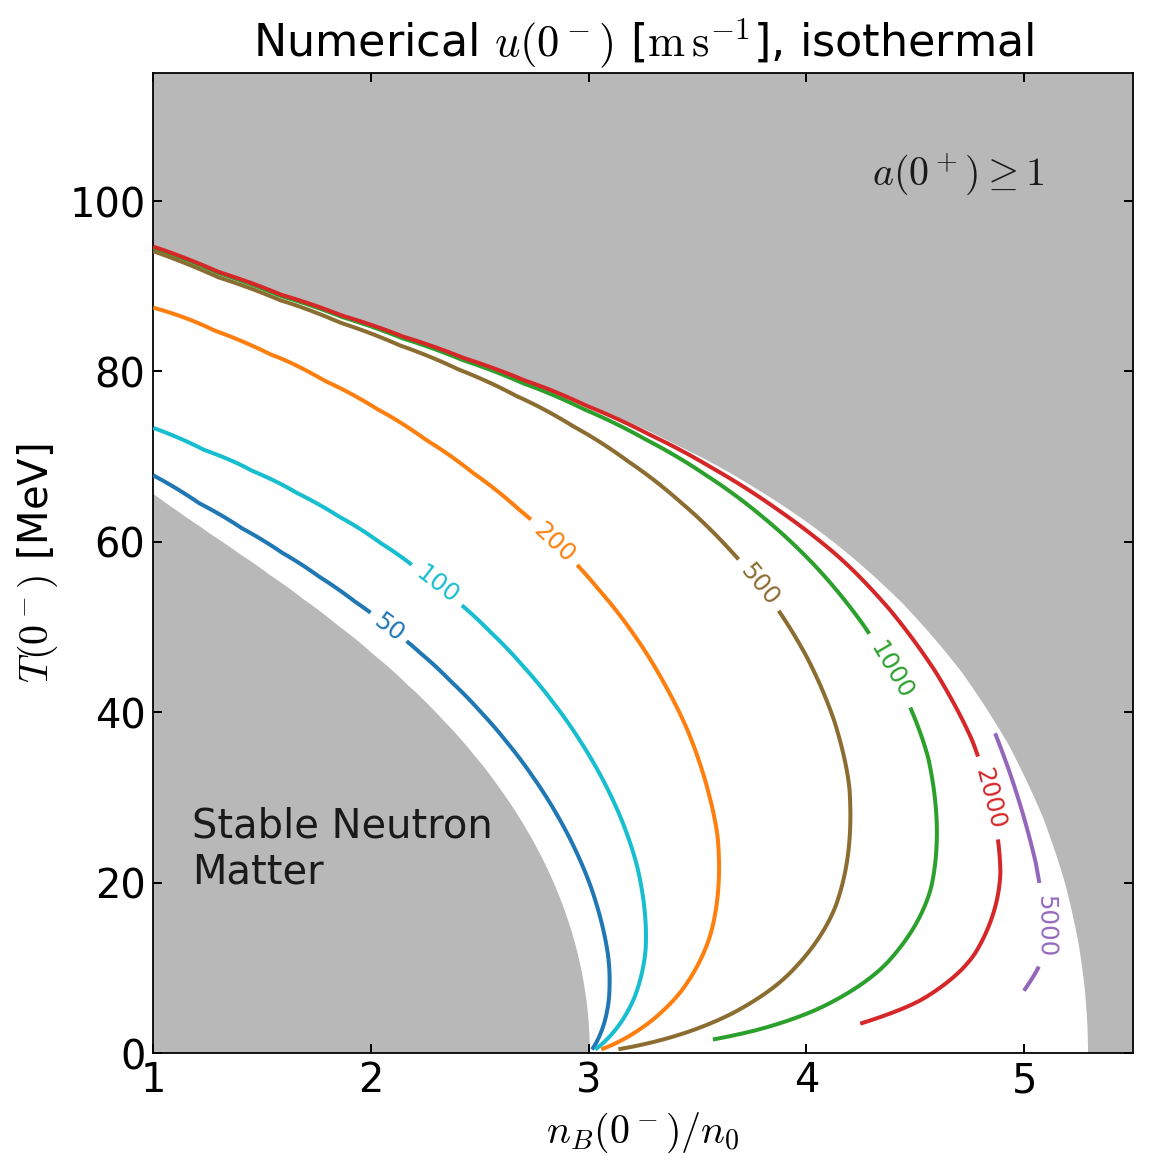

In [12]:
from pathlib import Path
import hashlib
import json
import numpy as np

ISOTHERMAL_CONTOUR_DATA_DIR = Path("local_analysis_results/All_Plots_new/isothermal_contour_data")
ISOTHERMAL_CONTOUR_ARCHIVE = ISOTHERMAL_CONTOUR_DATA_DIR / "isothermal-numerical-contour.npz"
isothermal_contour_manifest = json.loads((ISOTHERMAL_CONTOUR_DATA_DIR / "manifest.json").read_text())
if hashlib.sha256(ISOTHERMAL_CONTOUR_ARCHIVE.read_bytes()).hexdigest() != isothermal_contour_manifest["plot_archive_sha256"]:
    raise RuntimeError("Isothermal plot archive differs from its saved manifest")
with np.load(ISOTHERMAL_CONTOUR_ARCHIVE, allow_pickle=False) as archive:
    isothermal_contour_data = {key: archive[key].copy() for key in archive.files}
print(f"Loaded local numerical snapshot: {isothermal_contour_manifest['repair_evaluations']} repair evaluations")
print(f"Preserved baseline successes: {isothermal_contour_manifest['baseline_successes']}/{isothermal_contour_manifest['baseline_cells']}")
print(f"Accepted contour roots: {isothermal_contour_manifest['accepted_contour_roots']}")
print(f"New targeted-run results included: {isothermal_contour_manifest['targeted_present']}")

# Tunable plotting parameters
NUMERICAL_VELOCITY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0)
NUMERICAL_VELOCITY_CONTOUR_COLORS = ("#1f77b4", "#17becf", "#ff7f0e", "#8c6d31", "#2ca02c", "#d62728", "#9467bd")
NUMERICAL_VELOCITY_CONTOUR_LINE_STYLE = "-"
NUMERICAL_VELOCITY_CONTOUR_LINE_WIDTH = 1.8
NUMERICAL_CONTOUR_LABEL_FONT_SIZE = 11
NUMERICAL_CONTOUR_LABEL_FORMAT = "%g"
NUMERICAL_CONTOUR_LABEL_INLINE = True
NUMERICAL_CONTOUR_LABEL_INLINE_SPACING = 4
# Label each level where it is well separated from its neighbours: the low
# levels spread out at high temperature and the high ones at low temperature.
NUMERICAL_CONTOUR_LABEL_TEMPERATURES_MEV = {
    50.0: 50.0, 100.0: 55.0, 200.0: 60.0, 500.0: 55.0,
    1000.0: 45.0, 2000.0: 30.0, 5000.0: 15.0,
}
NUMERICAL_CONTOUR_ZORDER = 3
NUMERICAL_EXCLUDED_REGION_COLOR = "0.72"
NUMERICAL_EXCLUDED_REGION_ALPHA = 1.0
NUMERICAL_EXCLUDED_REGION_ZORDER = 0
NUMERICAL_OUTER_REGION_TEXT = r"$a(0^+)\geq 1$"
NUMERICAL_OUTER_REGION_TEXT_POSITION = (4.3, 102.0)
NUMERICAL_INNER_REGION_TEXT = "Stable Neutron\nMatter"
NUMERICAL_INNER_REGION_TEXT_POSITION = (1.18, 20.0)
NUMERICAL_REGION_TEXT_COLOR = "0.10"
NUMERICAL_REGION_TEXT_FONT_SIZE = 18
NUMERICAL_REGION_TEXT_ZORDER = 5
NUMERICAL_FIGURE_SIZE = (7.2, 7.2)
NUMERICAL_FIGURE_DPI = 160
NUMERICAL_EXPORT_DPI = 220
NUMERICAL_BACKGROUND_COLOR = "white"
NUMERICAL_CONSTRAINED_LAYOUT = True
NUMERICAL_MATHTEXT_FONTSET = "cm"
NUMERICAL_MATHTEXT_ROMAN = "serif"
NUMERICAL_MATHTEXT_ITALIC = "serif:italic"
NUMERICAL_MATHTEXT_BOLD = "serif:bold"
NUMERICAL_X_LIMITS = (1.0, 5.5)
NUMERICAL_Y_LIMITS_MEV = (0.0, 115.0)
NUMERICAL_X_SCALE = "linear"
NUMERICAL_Y_SCALE = "linear"
NUMERICAL_BOX_ASPECT = 1.0
NUMERICAL_TITLE = r"Numerical $u(0^-)$ [$\mathrm{m\,s^{-1}}$], isothermal"
NUMERICAL_TITLE_FONT_SIZE = 20
NUMERICAL_TITLE_PAD = 8
NUMERICAL_X_LABEL = r"$n_B(0^-)/n_0$"
NUMERICAL_Y_LABEL = r"$T(0^-)$ [MeV]"
NUMERICAL_AXIS_LABEL_FONT_SIZE = 18
NUMERICAL_TICK_LABEL_FONT_SIZE = 18
NUMERICAL_TICK_DIRECTION = "in"
NUMERICAL_TICKS_TOP = True
NUMERICAL_TICKS_RIGHT = True
NUMERICAL_TICK_LENGTH = 4
NUMERICAL_TICK_WIDTH = 0.9
NUMERICAL_SPINE_LINE_WIDTH = 0.8
NUMERICAL_OUTPUT_PNG = "local_analysis_results/All_Plots_new/isothermal-numerical-contour.png"
NUMERICAL_OUTPUT_PDF = "local_analysis_results/All_Plots_new/isothermal-numerical-contour.pdf"

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.contour import ContourSet
import numpy as np

# Plot-only arrays: independent of cluster folders and all EOS/BVP imports.
numerical_inner_density, numerical_inner_temperature = isothermal_contour_data["inner_boundary"].T
numerical_outer_density, numerical_outer_temperature = isothermal_contour_data["outer_boundary"].T
numerical_saved_levels = isothermal_contour_data["levels_m_s"].tolist()
numerical_level_to_color = dict(zip(NUMERICAL_VELOCITY_CONTOUR_LEVELS_M_S, NUMERICAL_VELOCITY_CONTOUR_COLORS))
# One solid polyline per level: interior gaps and bracketed open ends are
# already filled in the archive, so no markers or dashed pieces are drawn here.
# `curve_solved_{i}` records which nodes are accepted BVP roots; the counts are
# printed below so the interpolated fraction stays visible without clutter.
numerical_merged_segments = []
numerical_solved_node_counts = {}
for numerical_level in NUMERICAL_VELOCITY_CONTOUR_LEVELS_M_S:
    numerical_index = numerical_saved_levels.index(numerical_level)
    numerical_curve = isothermal_contour_data[f"curve_vertices_{numerical_index}"]
    numerical_solved = isothermal_contour_data[f"curve_solved_{numerical_index}"]
    numerical_merged_segments.append([numerical_curve] if len(numerical_curve) else [])
    numerical_solved_node_counts[numerical_level] = (
        int(numerical_solved.sum()), int(numerical_solved.size)
    )
numerical_success_grid = isothermal_contour_data["baseline_success_grid"]
numerical_success_count = int(np.count_nonzero(numerical_success_grid))
numerical_cell_count = numerical_success_grid.size
numerical_valid_velocities = isothermal_contour_data["baseline_velocity_grid"][numerical_success_grid]
numerical_velocity_min = float(np.min(numerical_valid_velocities))
numerical_velocity_max = float(np.max(numerical_valid_velocities))

with mpl.rc_context({
    "mathtext.fontset": NUMERICAL_MATHTEXT_FONTSET,
    "mathtext.rm": NUMERICAL_MATHTEXT_ROMAN,
    "mathtext.it": NUMERICAL_MATHTEXT_ITALIC,
    "mathtext.bf": NUMERICAL_MATHTEXT_BOLD,
}):
    numerical_figure, numerical_axis = plt.subplots(
        figsize=NUMERICAL_FIGURE_SIZE,
        dpi=NUMERICAL_FIGURE_DPI,
        constrained_layout=NUMERICAL_CONSTRAINED_LAYOUT,
        facecolor=NUMERICAL_BACKGROUND_COLOR,
    )
    numerical_axis.set_facecolor(NUMERICAL_BACKGROUND_COLOR)

    numerical_inner_polygon_x = np.concatenate(
        (
            numerical_inner_density,
            (NUMERICAL_X_LIMITS[0], numerical_inner_density[0]),
        )
    )
    numerical_inner_polygon_y = np.concatenate(
        (
            numerical_inner_temperature,
            (NUMERICAL_Y_LIMITS_MEV[0], NUMERICAL_Y_LIMITS_MEV[0]),
        )
    )
    numerical_axis.fill(
        numerical_inner_polygon_x,
        numerical_inner_polygon_y,
        color=NUMERICAL_EXCLUDED_REGION_COLOR,
        alpha=NUMERICAL_EXCLUDED_REGION_ALPHA,
        zorder=NUMERICAL_EXCLUDED_REGION_ZORDER,
    )
    numerical_outer_polygon_x = np.concatenate(
        (
            numerical_outer_density,
            (
                NUMERICAL_X_LIMITS[0],
                NUMERICAL_X_LIMITS[1],
                NUMERICAL_X_LIMITS[1],
                numerical_outer_density[0],
            ),
        )
    )
    numerical_outer_polygon_y = np.concatenate(
        (
            numerical_outer_temperature,
            (
                NUMERICAL_Y_LIMITS_MEV[1],
                NUMERICAL_Y_LIMITS_MEV[1],
                NUMERICAL_Y_LIMITS_MEV[0],
                NUMERICAL_Y_LIMITS_MEV[0],
            ),
        )
    )
    numerical_axis.fill(
        numerical_outer_polygon_x,
        numerical_outer_polygon_y,
        color=NUMERICAL_EXCLUDED_REGION_COLOR,
        alpha=NUMERICAL_EXCLUDED_REGION_ALPHA,
        zorder=NUMERICAL_EXCLUDED_REGION_ZORDER,
    )

    numerical_speed_contours = ContourSet(
        numerical_axis,
        NUMERICAL_VELOCITY_CONTOUR_LEVELS_M_S,
        numerical_merged_segments,
        colors=NUMERICAL_VELOCITY_CONTOUR_COLORS,
        linestyles=NUMERICAL_VELOCITY_CONTOUR_LINE_STYLE,
        linewidths=NUMERICAL_VELOCITY_CONTOUR_LINE_WIDTH,
        zorder=NUMERICAL_CONTOUR_ZORDER,
    )
    numerical_label_positions = [
        (
            np.interp(
                NUMERICAL_CONTOUR_LABEL_TEMPERATURES_MEV[numerical_level],
                numerical_curve[:, 1],
                numerical_curve[:, 0],
            ),
            NUMERICAL_CONTOUR_LABEL_TEMPERATURES_MEV[numerical_level],
        )
        for numerical_level, (numerical_curve,) in zip(
            NUMERICAL_VELOCITY_CONTOUR_LEVELS_M_S, numerical_merged_segments
        )
    ]
    numerical_axis.clabel(
        numerical_speed_contours,
        numerical_speed_contours.levels,
        inline=NUMERICAL_CONTOUR_LABEL_INLINE,
        fmt=NUMERICAL_CONTOUR_LABEL_FORMAT,
        fontsize=NUMERICAL_CONTOUR_LABEL_FONT_SIZE,
        inline_spacing=NUMERICAL_CONTOUR_LABEL_INLINE_SPACING,
        manual=numerical_label_positions,
    )
    numerical_axis.text(
        *NUMERICAL_OUTER_REGION_TEXT_POSITION,
        NUMERICAL_OUTER_REGION_TEXT,
        color=NUMERICAL_REGION_TEXT_COLOR,
        fontsize=NUMERICAL_REGION_TEXT_FONT_SIZE,
        zorder=NUMERICAL_REGION_TEXT_ZORDER,
    )
    numerical_axis.text(
        *NUMERICAL_INNER_REGION_TEXT_POSITION,
        NUMERICAL_INNER_REGION_TEXT,
        color=NUMERICAL_REGION_TEXT_COLOR,
        fontsize=NUMERICAL_REGION_TEXT_FONT_SIZE,
        zorder=NUMERICAL_REGION_TEXT_ZORDER,
    )
    numerical_axis.set_xlim(*NUMERICAL_X_LIMITS)
    numerical_axis.set_ylim(*NUMERICAL_Y_LIMITS_MEV)
    numerical_axis.set_xscale(NUMERICAL_X_SCALE)
    numerical_axis.set_yscale(NUMERICAL_Y_SCALE)
    numerical_axis.set_box_aspect(NUMERICAL_BOX_ASPECT)
    numerical_axis.set_xlabel(NUMERICAL_X_LABEL, fontsize=NUMERICAL_AXIS_LABEL_FONT_SIZE)
    numerical_axis.set_ylabel(NUMERICAL_Y_LABEL, fontsize=NUMERICAL_AXIS_LABEL_FONT_SIZE)
    numerical_axis.set_title(
        NUMERICAL_TITLE, fontsize=NUMERICAL_TITLE_FONT_SIZE, pad=NUMERICAL_TITLE_PAD
    )
    numerical_axis.tick_params(
        direction=NUMERICAL_TICK_DIRECTION,
        top=NUMERICAL_TICKS_TOP,
        right=NUMERICAL_TICKS_RIGHT,
        length=NUMERICAL_TICK_LENGTH,
        width=NUMERICAL_TICK_WIDTH,
        labelsize=NUMERICAL_TICK_LABEL_FONT_SIZE,
    )
    for numerical_spine in numerical_axis.spines.values():
        numerical_spine.set_linewidth(NUMERICAL_SPINE_LINE_WIDTH)

    numerical_output_png = Path.cwd() / NUMERICAL_OUTPUT_PNG
    numerical_output_pdf = Path.cwd() / NUMERICAL_OUTPUT_PDF
    numerical_output_png.parent.mkdir(parents=True, exist_ok=True)
    numerical_figure.savefig(
        numerical_output_png,
        dpi=NUMERICAL_EXPORT_DPI,
        facecolor=NUMERICAL_BACKGROUND_COLOR,
    )
    numerical_figure.savefig(
        numerical_output_pdf, facecolor=NUMERICAL_BACKGROUND_COLOR
    )
    print(
        f"Preserved baseline successes: {numerical_success_count}/"
        f"{numerical_cell_count}"
    )
    print(
        f"Baseline velocity range: {numerical_velocity_min:.2f}--"
        f"{numerical_velocity_max:.2f} m/s"
    )
    for numerical_level, (numerical_solved_count, numerical_node_count) in (
        numerical_solved_node_counts.items()
    ):
        print(
            f"  {numerical_level:>6g} m/s curve: {numerical_solved_count}/"
            f"{numerical_node_count} nodes are accepted BVP roots"
        )
    print(f"Saved {numerical_output_png}")
    print(f"Saved {numerical_output_pdf}")
    plt.show()

## Supplementary baseline grid diagnostics

These panels describe the original 600-cell checkpoint. The targeted repair above adds numerical contour points; it does not claim to have filled every unsuccessful original grid cell.


In [5]:
NUMERICAL_PAYLOAD_PATH = NUMERICAL_WORKFLOW_DIR / "isothermal-numerical.npy"
numerical_payload = np.load(NUMERICAL_PAYLOAD_PATH, allow_pickle=True).item()
if numerical_payload.get("payload_kind") != "isothermal_numerical":
    raise RuntimeError("Unexpected numerical payload kind")
if numerical_payload.get("domain_fingerprint") != numerical_domain_payload.get("domain_fingerprint"):
    raise RuntimeError("Domain and numerical checkpoint fingerprints differ")
numerical_task_status = np.asarray(numerical_payload["task_status"], dtype=object)
numerical_status_names, numerical_status_counts = np.unique(
    numerical_task_status, return_counts=True
)
print(f"Numerical run complete: {bool(numerical_payload.get('run_complete'))}")
for numerical_status_name, numerical_status_count in zip(
    numerical_status_names, numerical_status_counts
):
    print(f"  {numerical_status_name}: {int(numerical_status_count)}")

Numerical run complete: True
  cell_timeout: 194
  failure: 44
  success: 362


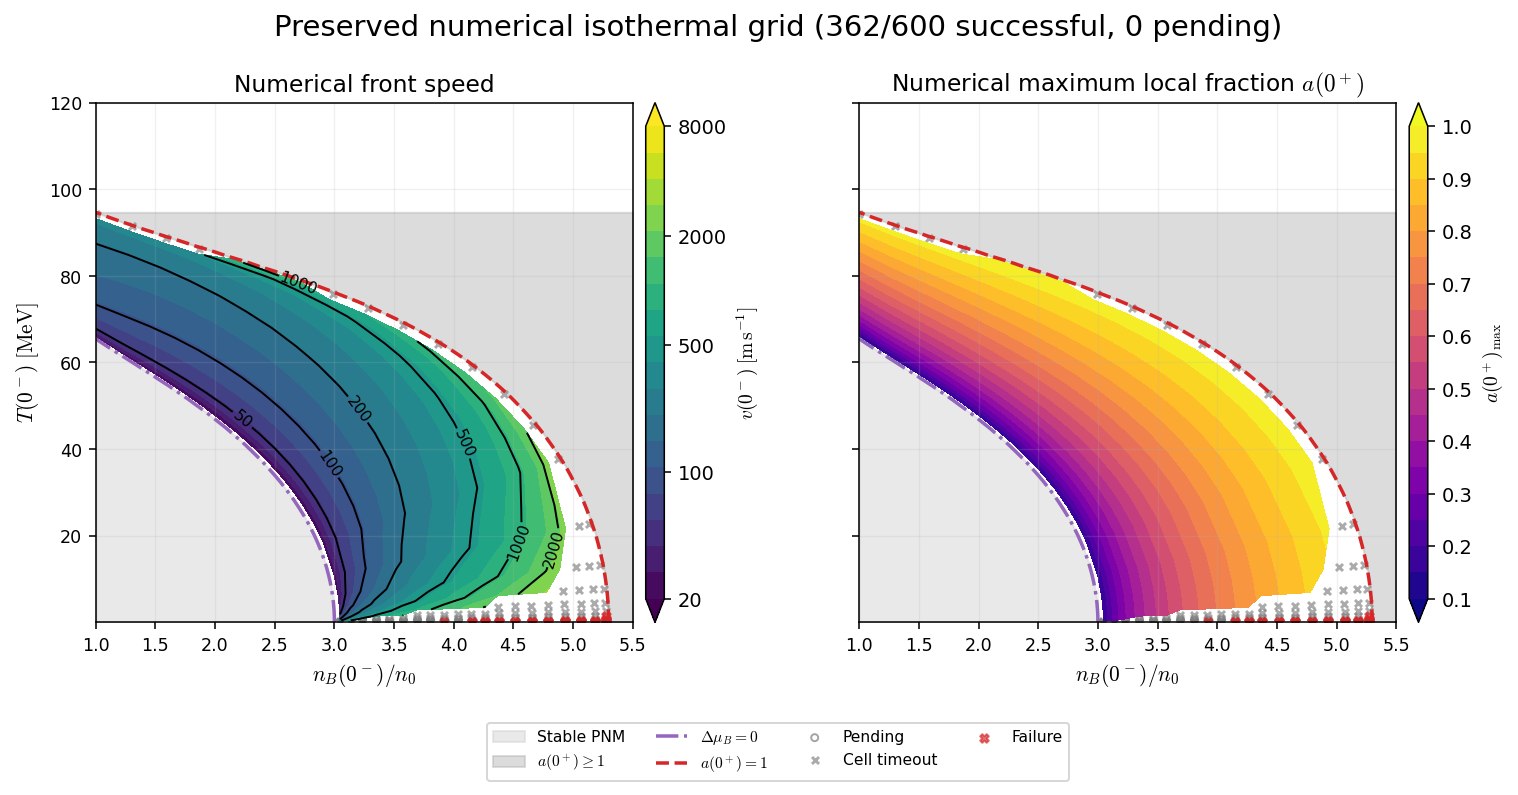

In [6]:
# Tunable plotting parameters
NUMERICAL_FIGURE_SIZE = (13.0, 5.8)
NUMERICAL_FIGURE_DPI = 140
NUMERICAL_TITLE_FONT_SIZE = 15
NUMERICAL_PANEL_TITLE_FONT_SIZE = 12
NUMERICAL_AXIS_LABEL_FONT_SIZE = 11
NUMERICAL_TICK_LABEL_FONT_SIZE = 9
NUMERICAL_COLORBAR_LABEL_FONT_SIZE = 10
NUMERICAL_LEGEND_FONT_SIZE = 8
NUMERICAL_CONTOUR_LABEL_FONT_SIZE = 8
NUMERICAL_BOUNDARY_LINE_WIDTH = 1.8
NUMERICAL_CONTOUR_LINE_WIDTH = 1.0
NUMERICAL_GRID_LINE_WIDTH = 0.7
NUMERICAL_STATUS_MARKER_SIZE = 13.0
NUMERICAL_FAILURE_MARKER_SIZE = 20.0
NUMERICAL_STATUS_ALPHA = 0.65
NUMERICAL_REGION_ALPHA = 0.42
NUMERICAL_GRID_ALPHA = 0.18
NUMERICAL_SPEED_LEVELS_M_S = np.geomspace(20.0, 8000.0, 19)
NUMERICAL_SPEED_LINES_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0)
NUMERICAL_SPEED_TICKS_M_S = (20.0, 100.0, 500.0, 2000.0, 8000.0)
NUMERICAL_SPEED_TICK_LABELS = ("20", "100", "500", "2000", "8000")
NUMERICAL_COMPOSITION_LEVELS = np.linspace(0.1, 1.0, 19)
NUMERICAL_SPEED_COLORMAP = "viridis"
NUMERICAL_COMPOSITION_COLORMAP = "plasma"
NUMERICAL_STABLE_COLOR = "0.80"
NUMERICAL_FORBIDDEN_COLOR = "0.68"
NUMERICAL_LOWER_BOUNDARY_COLOR = "tab:purple"
NUMERICAL_UPPER_BOUNDARY_COLOR = "tab:red"
NUMERICAL_PENDING_COLOR = "0.45"
NUMERICAL_TIMEOUT_COLOR = "tab:gray"
NUMERICAL_FAILURE_COLOR = "tab:red"
NUMERICAL_CONTOUR_COLOR = "k"
NUMERICAL_X_LIMITS = (1.0, 5.5)
NUMERICAL_Y_LIMITS_MEV = (0.01, 120.0)
NUMERICAL_COLORBAR_PAD = 0.02
NUMERICAL_COLORBAR_ASPECT = 28
NUMERICAL_LEGEND_COLUMNS = 4
NUMERICAL_LEGEND_BBOX = (0.5, 0.015)
NUMERICAL_SUBPLOT_BOTTOM = 0.22
NUMERICAL_SUBPLOT_TOP = 0.86
NUMERICAL_SUBPLOT_WSPACE = 0.18
NUMERICAL_SUPTITLE_Y = 0.97

from matplotlib.colors import LogNorm

lower_density = numerical_inner_density
lower_temperature = numerical_inner_temperature
upper_density = numerical_outer_density
upper_temperature = numerical_outer_temperature
finite_boundary = (
    np.isfinite(lower_density)
    & np.isfinite(lower_temperature)
    & np.isfinite(upper_density)
    & np.isfinite(upper_temperature)
)
density_grid = numerical_density_grid
temperature_grid = numerical_temperature_grid

numerical_velocity_m_s = np.asarray(numerical_payload["velocity_m_s_grid"], dtype=float)
numerical_a_0plus_max = np.asarray(numerical_payload["a_0plus_max_grid"], dtype=float)
numerical_success_velocity = (
    (numerical_task_status == "success")
    & np.isfinite(numerical_velocity_m_s)
    & (numerical_velocity_m_s > 0.0)
)
numerical_success_composition = (
    (numerical_task_status == "success") & np.isfinite(numerical_a_0plus_max)
)
numerical_velocity_masked = np.ma.masked_where(~numerical_success_velocity, numerical_velocity_m_s)
numerical_composition_masked = np.ma.masked_where(
    ~numerical_success_composition, numerical_a_0plus_max
)
pending_mask = numerical_task_status == "pending"
cell_timeout_mask = numerical_task_status == "cell_timeout"
failure_mask = numerical_task_status == "failure"

numerical_figure, numerical_axes = plt.subplots(
    1, 2, figsize=NUMERICAL_FIGURE_SIZE, dpi=NUMERICAL_FIGURE_DPI,
    sharex=True, sharey=True,
)
for numerical_axis in numerical_axes:
    numerical_axis.fill_betweenx(
        lower_temperature[finite_boundary], NUMERICAL_X_LIMITS[0], lower_density[finite_boundary],
        color=NUMERICAL_STABLE_COLOR, alpha=NUMERICAL_REGION_ALPHA, label="Stable PNM",
    )
    numerical_axis.fill_betweenx(
        upper_temperature[finite_boundary], upper_density[finite_boundary], NUMERICAL_X_LIMITS[1],
        color=NUMERICAL_FORBIDDEN_COLOR, alpha=NUMERICAL_REGION_ALPHA,
        label=r"$a(0^+) \geq 1$",
    )
    numerical_axis.plot(
        lower_density[finite_boundary], lower_temperature[finite_boundary],
        color=NUMERICAL_LOWER_BOUNDARY_COLOR, linestyle="-.",
        linewidth=NUMERICAL_BOUNDARY_LINE_WIDTH, label=r"$\Delta\mu_B=0$",
    )
    numerical_axis.plot(
        upper_density[finite_boundary], upper_temperature[finite_boundary],
        color=NUMERICAL_UPPER_BOUNDARY_COLOR, linestyle="--",
        linewidth=NUMERICAL_BOUNDARY_LINE_WIDTH, label=r"$a(0^+)=1$",
    )
    numerical_axis.scatter(
        density_grid[pending_mask], temperature_grid[pending_mask], facecolors="none",
        edgecolors=NUMERICAL_PENDING_COLOR, s=NUMERICAL_STATUS_MARKER_SIZE,
        alpha=NUMERICAL_STATUS_ALPHA, label="Pending",
    )
    numerical_axis.scatter(
        density_grid[cell_timeout_mask], temperature_grid[cell_timeout_mask],
        color=NUMERICAL_TIMEOUT_COLOR, marker="x", s=NUMERICAL_STATUS_MARKER_SIZE,
        alpha=NUMERICAL_STATUS_ALPHA, label="Cell timeout",
    )
    numerical_axis.scatter(
        density_grid[failure_mask], temperature_grid[failure_mask],
        color=NUMERICAL_FAILURE_COLOR, marker="X", s=NUMERICAL_FAILURE_MARKER_SIZE,
        alpha=NUMERICAL_STATUS_ALPHA, label="Failure",
    )
    numerical_axis.set(
        xlim=NUMERICAL_X_LIMITS, ylim=NUMERICAL_Y_LIMITS_MEV, xlabel=r"$n_B(0^-)/n_0$"
    )
    numerical_axis.xaxis.label.set_size(NUMERICAL_AXIS_LABEL_FONT_SIZE)
    numerical_axis.tick_params(labelsize=NUMERICAL_TICK_LABEL_FONT_SIZE)
    numerical_axis.grid(alpha=NUMERICAL_GRID_ALPHA, linewidth=NUMERICAL_GRID_LINE_WIDTH)

numerical_speed_fill = numerical_axes[0].contourf(
    density_grid, temperature_grid, numerical_velocity_masked,
    levels=NUMERICAL_SPEED_LEVELS_M_S,
    norm=LogNorm(vmin=NUMERICAL_SPEED_LEVELS_M_S[0], vmax=NUMERICAL_SPEED_LEVELS_M_S[-1]),
    cmap=NUMERICAL_SPEED_COLORMAP, extend="both",
)
numerical_speed_lines = numerical_axes[0].contour(
    density_grid, temperature_grid, numerical_velocity_masked,
    levels=NUMERICAL_SPEED_LINES_M_S, colors=NUMERICAL_CONTOUR_COLOR,
    linewidths=NUMERICAL_CONTOUR_LINE_WIDTH,
)
numerical_axes[0].clabel(
    numerical_speed_lines, fontsize=NUMERICAL_CONTOUR_LABEL_FONT_SIZE, fmt="%g"
)
numerical_axes[0].set_title("Numerical front speed", fontsize=NUMERICAL_PANEL_TITLE_FONT_SIZE)
numerical_axes[0].set_ylabel(
    r"$T(0^-)\;[\mathrm{MeV}]$", fontsize=NUMERICAL_AXIS_LABEL_FONT_SIZE
)
numerical_speed_colorbar = numerical_figure.colorbar(
    numerical_speed_fill, ax=numerical_axes[0],
    pad=NUMERICAL_COLORBAR_PAD, aspect=NUMERICAL_COLORBAR_ASPECT,
)
numerical_speed_colorbar.set_label(
    r"$v(0^-)\;[\mathrm{m\,s^{-1}}]$", fontsize=NUMERICAL_COLORBAR_LABEL_FONT_SIZE
)
numerical_speed_colorbar.set_ticks(NUMERICAL_SPEED_TICKS_M_S)
numerical_speed_colorbar.set_ticklabels(NUMERICAL_SPEED_TICK_LABELS)

numerical_composition_fill = numerical_axes[1].contourf(
    density_grid, temperature_grid, numerical_composition_masked,
    levels=NUMERICAL_COMPOSITION_LEVELS, cmap=NUMERICAL_COMPOSITION_COLORMAP,
    extend="both",
)
numerical_axes[1].set_title(
    r"Numerical maximum local fraction $a(0^+)$", fontsize=NUMERICAL_PANEL_TITLE_FONT_SIZE
)
numerical_composition_colorbar = numerical_figure.colorbar(
    numerical_composition_fill, ax=numerical_axes[1],
    pad=NUMERICAL_COLORBAR_PAD, aspect=NUMERICAL_COLORBAR_ASPECT,
)
numerical_composition_colorbar.set_label(
    r"$a(0^+)_{\max}$", fontsize=NUMERICAL_COLORBAR_LABEL_FONT_SIZE
)
numerical_handles, numerical_labels = numerical_axes[0].get_legend_handles_labels()
numerical_figure.legend(
    numerical_handles, numerical_labels, loc="lower center",
    ncol=NUMERICAL_LEGEND_COLUMNS, bbox_to_anchor=NUMERICAL_LEGEND_BBOX,
    fontsize=NUMERICAL_LEGEND_FONT_SIZE,
)
numerical_figure.subplots_adjust(
    bottom=NUMERICAL_SUBPLOT_BOTTOM, top=NUMERICAL_SUBPLOT_TOP,
    wspace=NUMERICAL_SUBPLOT_WSPACE,
)
numerical_figure.suptitle(
    (
        f"Preserved numerical isothermal grid "
        f"({numerical_success_velocity.sum()}/{numerical_task_status.size} successful, "
        f"{pending_mask.sum()} pending)"
    ),
    fontsize=NUMERICAL_TITLE_FONT_SIZE, y=NUMERICAL_SUPTITLE_Y,
)
plt.show()